# 02 · Stimulus statistics + gradient descent: efficient coding, mixing and disentangling

**Question 5.** *How do mixed selectivity and disentanglement relate to the statistics of the environment and to
gradient-descent learning — the same mechanism that makes efficient codes emerge (Benjamin, Zhang & Kording 2022)?*

Gradient descent weights every update by how often a stimulus occurs. Two consequences we test:
1. **Within a factor** — frequent values receive more sensitivity (Fisher information ∝ prior², i.e.
   √FI ∝ p(θ)): efficient coding *emerges* during learning.
2. **Across factors** — in early learning GD picks up the dominant directions of the input–output
   covariance first (Saxe et al. 2014). With *correlated* factors these directions are mixtures
   (f1+f2, f1−f2), so representations pass through a **mixed phase**; energy + non-negativity then
   pull them towards factor axes only if the support is rectangular (notebook 01).

Sections: (1) correlation × support sweep, (2) learning trajectories and rich vs lazy initialisation,
(3) efficient coding of orientation with a cardinal prior, (4) a skewed factor in 2-D.

In [1]:
import os, sys, json, time
import numpy as np
import torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
from mixdis import data, models, metrics, dendrite, rnn
from mixdis.utils import save_json, load_json, set_threads

# FAST=1 -> tiny smoke-test run (minutes). Unset/0 -> full experiment.
FAST = os.environ.get("FAST", "0") == "1"
set_threads()
RES = os.path.abspath("../results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(RES, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
def savefig(name):
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", dpi=200)
    plt.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
print("FAST mode:", FAST, "| torch", torch.__version__, "| threads", torch.get_num_threads())

FAST mode: False | torch 2.14.1 | threads 7


In [2]:
K, H, D = 2, 6, 30
obs = data.RandomObservation(K, D, "linear", seed=0)
STEPS = 300 if FAST else 4000
SEEDS = [0] if FAST else [0, 1, 2, 3]
NS = 1500 if FAST else 4000
LAM = 1e-2

## 1. Factor dependence: correlation vs support

support full   rho 0.00: disent 0.59 ± 0.23
support full   rho 0.20: disent 0.43 ± 0.28
support full   rho 0.40: disent 0.57 ± 0.25
support full   rho 0.60: disent 0.65 ± 0.28
support full   rho 0.80: disent 0.70 ± 0.19
support full   rho 0.95: disent 0.63 ± 0.06
support corner rho 0.00: disent 0.63 ± 0.06
support corner rho 0.20: disent 0.66 ± 0.02
support corner rho 0.40: disent 0.69 ± 0.04
support corner rho 0.60: disent 0.63 ± 0.15
support corner rho 0.80: disent 0.63 ± 0.20
support corner rho 0.95: disent 0.61 ± 0.04


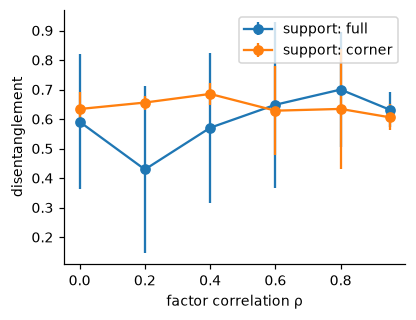

In [3]:
RHOS = [0.0, 0.8] if FAST else [0.0, 0.2, 0.4, 0.6, 0.8, 0.95]
R1 = {}
for sup in ["full", "corner"]:
    for rho in RHOS:
        vals = []
        for seed in SEEDS:
            F = data.sample_factors(NS, K, corr=rho, support=sup, rng=np.random.default_rng(seed)); X = obs(F)
            m = models.Autoencoder(D, H, act="relu", seed=seed)
            models.train(m, X, None, "recon", steps=STEPS, act_l2=LAM, w_l2=LAM / 10, seed=seed)
            vals.append(metrics.disentanglement(models.hidden(m, X), F)[0])
        R1[(sup, rho)] = vals
        print(f"support {sup:6s} rho {rho:.2f}: disent {np.nanmean(vals):.2f} ± {np.nanstd(vals):.2f}")
plt.figure(figsize=(4, 3))
for sup, c in [("full", "tab:blue"), ("corner", "tab:orange")]:
    M = np.array([R1[(sup, r)] for r in RHOS])
    plt.errorbar(RHOS, np.nanmean(M, 1), np.nanstd(M, 1), marker="o", color=c, label=f"support: {sup}")
plt.xlabel("factor correlation ρ"); plt.ylabel("disentanglement"); plt.legend(); savefig("02_dependence_sweep"); plt.show()

**Result (4 seeds).** No systematic effect of correlation on disentanglement, for either support: full support 0.43–0.70 (seed s.d.
0.06–0.28), corner support 0.61–0.69. Consistent with notebook 01: correlation alone does not decide whether codes mix.

## 2. Learning trajectories: transient mixing and the rich vs lazy regime

ρ=0, rich disent start→end: [0.62 0.64 0.92]
ρ=0.8, rich disent start→end: [0.73 0.46 0.85]
diamond (ρ=0), rich disent start→end: [0.63 0.51 0.17]
ρ=0, lazy disent start→end: [0.53 0.52 0.9 ]


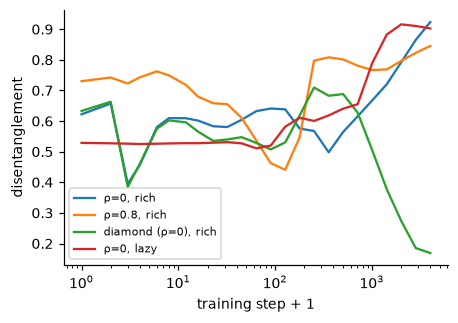

In [4]:
SNAPS = sorted(set(np.unique(np.geomspace(1, STEPS, 25).astype(int)).tolist() + [0]))
R2 = {}
for nm, kw, init in [("ρ=0, rich", dict(corr=0.0), 0.1), ("ρ=0.8, rich", dict(corr=0.8), 0.1),
                     ("diamond (ρ=0), rich", dict(support="diamond"), 0.1), ("ρ=0, lazy", dict(corr=0.0), 3.0)]:
    traj = []
    for seed in SEEDS[:2]:
        F = data.sample_factors(NS, K, rng=np.random.default_rng(seed), **kw); X = obs(F)
        m = models.Autoencoder(D, H, act="relu", init_scale=init, seed=seed)
        h = models.train(m, X, None, "recon", steps=STEPS, act_l2=LAM, w_l2=LAM / 10, snapshots=SNAPS, lr=1e-3, seed=seed)
        traj.append([metrics.disentanglement(h["snap"][s][:1500], F[:1500])[0] for s in SNAPS])
    R2[nm] = np.array(traj)
    print(nm, "disent start→end:", np.round(np.nanmean(R2[nm], 0)[[0, len(SNAPS)//2, -1]], 2))
plt.figure(figsize=(4.5, 3))
for nm, T in R2.items():
    plt.plot(np.array(SNAPS) + 1, np.nanmean(T, 0), label=nm)
plt.xscale("log"); plt.xlabel("training step + 1"); plt.ylabel("disentanglement"); plt.legend(fontsize=7)
savefig("02_learning_trajectories"); plt.show()

**Result (2 seeds).**

| condition | start | minimum during learning | end |
|---|---|---|---|
| ρ = 0, rich | 0.62 | 0.40 (step 2) | 0.92 |
| ρ = 0.8, rich | 0.73 | **0.44 (step 126)** | 0.85 |
| diamond (ρ = 0), rich | 0.63 | 0.17 (end) | **0.17** |
| ρ = 0, lazy (large init) | 0.53 | 0.51 | 0.90 |

* Correlated factors pass through a **transient mixed phase** (minimum at step ≈ 126) before disentangling, as predicted from
  gradient descent learning the covariance modes first.
* With the diamond support, learning moves the code steadily *towards* mixing (w.r.t. the factors), ending at 0.17.
* The large-initialisation network ends as disentangled as the small-initialisation one: with Adam and these sizes, a true lazy
  regime was not reached (see notebook 03).

## 3. Efficient coding of orientation emerges through gradient descent

Orientations follow the natural-image prior $p(\theta)\propto e^{\kappa\cos 4\theta}$ (more cardinal than
oblique edges). A one-hidden-layer ReLU network reads orientation (as $\cos2\theta,\sin2\theta$) from a noisy
population of input channels, trained with plain SGD from small weights. We track the hidden layer's
Fisher information $FI(\theta)=\|\partial z/\partial\theta\|^2$ (unit noise) over learning.

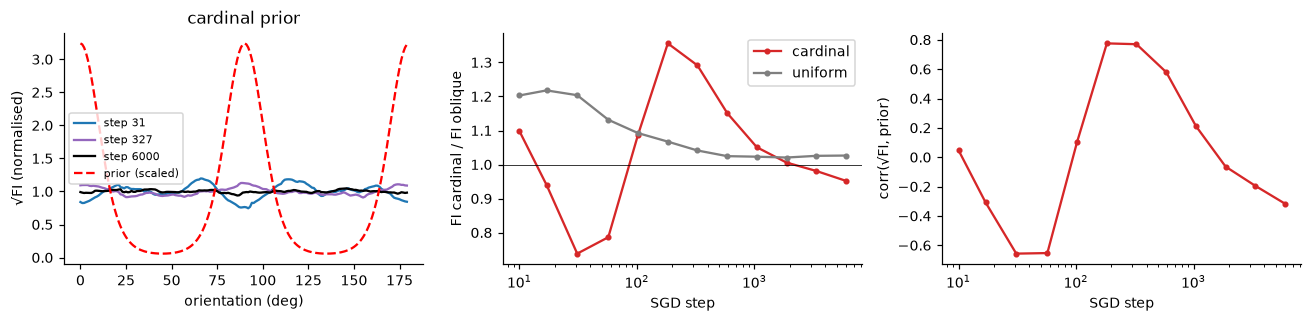

In [5]:
grid = np.linspace(0, np.pi, 180, endpoint=False).astype(np.float32)
ESTEPS = 400 if FAST else 6000
ESNAPS = sorted(set(np.unique(np.geomspace(10, ESTEPS, 12).astype(int)).tolist()))
card = (np.minimum(grid % (np.pi / 2), np.pi / 2 - grid % (np.pi / 2)) < np.radians(10))
obl = np.abs(grid % (np.pi / 2) - np.pi / 4) < np.radians(10)
def fisher(Z):
    dZ = (np.roll(Z, -1, 0) - np.roll(Z, 1, 0)) / (2 * (grid[1] - grid[0])); return (dZ ** 2).sum(1)
R3 = {}
for prior in ["cardinal", "uniform"]:
    out = []
    for seed in SEEDS[:2]:
        rng = np.random.default_rng(seed)
        th = data.sample_angles(20000, prior, rng=rng)
        X = data.angle_observation(th, noise=0.1, rng=rng); Y = np.c_[np.cos(2 * th), np.sin(2 * th)].astype(np.float32)
        m = models.MultiTaskNet(X.shape[1], 100, 2, act="relu", init_scale=0.3, seed=seed)
        h = models.train(m, X, Y, "mse", steps=ESTEPS, lr=0.05, batch=32, opt="sgd", snapshots=ESNAPS,
                         Xs_snap=data.angle_observation(grid), seed=seed)
        out.append({s: fisher(h["snap"][s]) for s in ESNAPS})
    R3[prior] = out
p_card = data.prior_density(grid, "cardinal")
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for s, c in zip([ESNAPS[2], ESNAPS[len(ESNAPS) // 2], ESNAPS[-1]], ["tab:blue", "tab:purple", "k"]):
    fi = np.mean([o[s] for o in R3["cardinal"]], 0)
    axs[0].plot(np.degrees(grid), np.sqrt(fi) / np.sqrt(fi).mean(), color=c, label=f"step {s}")
axs[0].plot(np.degrees(grid), p_card / p_card.mean(), "r--", label="prior (scaled)")
axs[0].set_xlabel("orientation (deg)"); axs[0].set_ylabel("√FI (normalised)"); axs[0].legend(fontsize=7); axs[0].set_title("cardinal prior")
for prior, c in [("cardinal", "tab:red"), ("uniform", "tab:gray")]:
    ratio = np.array([[o[s][card].mean() / o[s][obl].mean() for s in ESNAPS] for o in R3[prior]])
    axs[1].plot(ESNAPS, ratio.mean(0), "-o", ms=3, color=c, label=prior)
    if prior == "cardinal":
        cor = np.array([[np.corrcoef(np.sqrt(o[s]), p_card)[0, 1] for s in ESNAPS] for o in R3[prior]])
        axs[2].plot(ESNAPS, cor.mean(0), "-o", ms=3, color=c)
axs[1].axhline(1, color="k", lw=0.5); axs[1].set_xscale("log"); axs[1].set_xlabel("SGD step"); axs[1].set_ylabel("FI cardinal / FI oblique"); axs[1].legend()
axs[2].set_xscale("log"); axs[2].set_xlabel("SGD step"); axs[2].set_ylabel("corr(√FI, prior)")
plt.tight_layout(); savefig("02_efficient_coding_emerges"); plt.show()

**Result.** Efficient coding emerges **transiently** through SGD. With the cardinal prior, the Fisher-information ratio
cardinal/oblique peaks at **1.36 at step ≈ 180** (1.38 and 1.33 for the two seeds) and corr(√FI, prior) peaks at **0.78**; the
uniform-prior control is at 1.07 at the same step (it starts slightly above 1 because of the input-channel geometry and decays to 1.03).
With continued training both measures fade (ratio 0.95 and corr −0.32 at step 6000) because the network has capacity to learn all
orientations equally well. Efficient allocation is a signature of **resource- or time-limited** learning, as in Benjamin et al. (2022).

## 4. A skewed factor in 2-D: frequency-weighted learning vs activity energy
Factor 1 has a skewed marginal (frequent low values), factor 2 is uniform. We measure (i) disentanglement and
(ii) the population's sensitivity to factor 1 as a function of its value, compared with the marginal density.
Two pressures compete here: frequency-weighted gradient descent (more sensitivity where values are frequent, as in
Section 3) and the activity-energy cost of non-negative neurons (place the *silent* part of each neuron's range at the
frequent values, which moves sensitivity towards rare values — sparse coding). The sign of corr(√sensitivity, density)
says which wins; repeat with correlated factors to see whether the allocation spills into mixing.

independent        disent 0.93  corr(√sens, density) -0.83
correlated ρ=0.6   disent 0.87  corr(√sens, density) -0.86


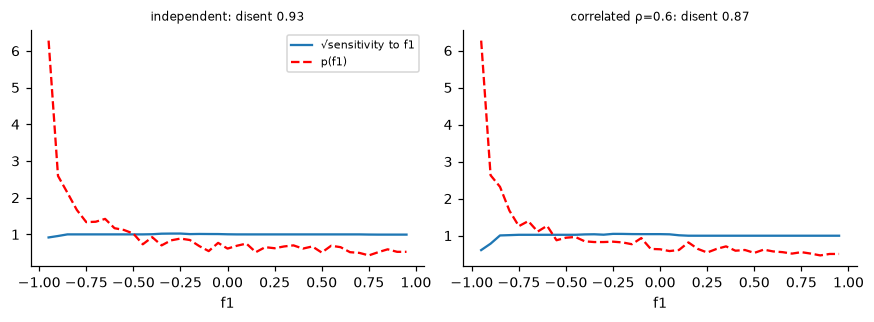

saved


In [6]:
R4 = {}
g1 = np.linspace(-0.95, 0.95, 39).astype(np.float32)
for nm, rho in [("independent", 0.0), ("correlated ρ=0.6", 0.6)]:
    rr = np.random.default_rng(0)
    F = data.sample_factors(NS, 2, corr=rho, rng=rr)
    F[:, 0] = 2 * ((F[:, 0] + 1) / 2) ** 2 - 1      # skew factor 1 towards -1
    X = obs(F)
    m = models.Autoencoder(D, 12, act="relu", seed=0)
    models.train(m, X, None, "recon", steps=STEPS, act_l2=LAM, w_l2=LAM / 10)
    Z = models.hidden(m, X)
    # sensitivity to f1 along a line with f2 = 0
    Fg = np.c_[g1, np.zeros_like(g1)]; Zg = models.hidden(m, obs(Fg))
    sens = (np.gradient(Zg, g1, axis=0) ** 2).sum(1)
    dens, edges = np.histogram(F[:, 0], bins=39, range=(-1, 1), density=True)
    R4[nm] = dict(disent=metrics.disentanglement(Z, F)[0], sens=sens, dens=dens)
    print(f"{nm:18s} disent {R4[nm]['disent']:.2f}  corr(√sens, density) {np.corrcoef(np.sqrt(sens), dens)[0,1]:.2f}")
fig, axs = plt.subplots(1, 2, figsize=(8, 3))
for ax, (nm, r) in zip(axs, R4.items()):
    ax.plot(g1, np.sqrt(r["sens"]) / np.sqrt(r["sens"]).mean(), label="√sensitivity to f1")
    ax.plot(g1, r["dens"] / r["dens"].mean(), "r--", label="p(f1)")
    ax.set_title(f"{nm}: disent {r['disent']:.2f}", fontsize=8); ax.set_xlabel("f1")
axs[0].legend(fontsize=7); plt.tight_layout(); savefig("02_skewed_factor"); plt.show()
save_json({"R1": {f"{k[0]}|{k[1]}": v for k, v in R1.items()}, "RHOS": RHOS,
           "R2": {k: v for k, v in R2.items()}, "SNAPS": SNAPS,
           "R3": {p: [{str(s): fi for s, fi in o.items()} for o in v] for p, v in R3.items()}, "ESNAPS": ESNAPS,
           "R4": R4}, os.path.join(RES, "nb02_statistics_gd.json")); print("saved")

**Result.** For a skewed factor, sensitivity is **anti-correlated** with stimulus density (r = −0.83 independent, −0.86 correlated),
while disentanglement stays high (0.93 / 0.87). Here the activity-energy cost dominates frequency weighting: frequent values are coded by
**silence** and rare values by firing (sparse, novelty-weighted coding). Which regime a circuit is in should depend on its energy budget.

### Summary of notebook 02
* Correlation between factors does not decide mixing (no trend from ρ = 0 to 0.95).
* Gradient descent produces a transient mixed phase for correlated factors (0.73 → 0.44 → 0.85) and drives codes towards mixing
  when the support is rotated (0.63 → 0.17).
* Efficient coding of orientation emerges mid-learning (FI ratio 1.36, corr 0.78) and fades with over-training.
* With an activity cost, frequent values are encoded by silence (r ≈ −0.85): energy efficiency and Fisher efficiency make opposite
  predictions, and the energy budget picks the winner.